# IBM Quantum Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 4: Quantum Correlation Switch

**Goal:** Design a two-qubit circuit that produces **correlated** outcomes (`00` and `11`), then switch it, with one small change, to produce **opposite** outcomes (`01` and `10`). Run each for **100 shots** and compare with histograms.

**Design constraints satisfied:**
- exactly 2 qubits, both measured
- at most 4 gates before measurement (Part A uses 2 gates, Part B uses 3 gates)
- only workshop gates: **H** (Hadamard), **CNOT** (`cx`) and **X**
- built and executed with Qiskit, 100 shots per experiment

**Qiskit bit-order note:** result strings are written as `q1 q0` (qubit 1 on the left, qubit 0 on the right).

## Step 0: Setup

In [1]:
# Install dependencies (skip if already installed)
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from math import sqrt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
STATES = ['00', '01', '10', '11']
backend = AerSimulator()


def run_circuit(qc, shots=SHOTS):
    """Execute a measured circuit and always return counts for all four outcomes."""
    compiled = transpile(qc, backend)
    raw = backend.run(compiled, shots=shots).result().get_counts()
    return {s: raw.get(s, 0) for s in STATES}


def exact_probabilities(core):
    """Exact theoretical probabilities of the 4 outcomes (used to check the predictions)."""
    d = Statevector(core).probabilities_dict()
    return {s: float(d.get(s, 0.0)) for s in STATES}


def nonzero(counts):
    """Counts with zero entries removed (cleaner printing and histograms)."""
    return {k: v for k, v in counts.items() if v > 0}


def within_noise(count, p, shots=SHOTS, k=4):
    """True if a count is within k standard deviations of the expected value shots*p."""
    sd = sqrt(shots * p * (1 - p))
    return abs(count - shots * p) <= k * sd + 1

## Predictions (made before running)

**Part A (H on qubit 0, then CNOT):** this prepares the Bell state (|00> + |11>)/sqrt(2).
- Dominant outcomes: **`00` and `11`**, each about 50% (about 50 shots each).
- `01` and `10` should not appear.

**Part B (same circuit plus an X gate on qubit 1):** the X gate flips qubit 1, giving (|01> + |10>)/sqrt(2).
- Dominant outcomes: **`01` and `10`**, each about 50%.
- `00` and `11` should not appear.

**Will all four outcomes appear?** No. In each circuit only two of the four outcomes appear, and the other two have probability 0 (in the ideal simulator). The qubits are entangled, so they are not independent: knowing one qubit's result fixes the other.

**Why are some outcomes much more frequent than others?** The Hadamard puts qubit 0 in an equal superposition and the CNOT copies that choice onto qubit 1 (entanglement). Only the outcomes where the two qubits are consistent with the entangled state have non-zero amplitude, so the other two outcomes are never measured.

## Part A: Correlated outcomes (00 and 11)

**Circuit:** H on qubit 0, CNOT (control qubit 0, target qubit 1), measure both qubits. (2 gates before measurement)

In [3]:
# Part A circuit without measurement (for the exact prediction)
core_a = QuantumCircuit(2)
core_a.h(0)
core_a.cx(0, 1)

# Part A circuit that is executed
qc_a = QuantumCircuit(2, 2, name='Part A')
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure([0, 1], [0, 1])

print('PART A CIRCUIT (correlated outcomes)')
print(qc_a.draw('text'))
pred_a = exact_probabilities(core_a)
print('\nPredicted probabilities:', {k: round(v, 3) for k, v in pred_a.items()})

PART A CIRCUIT (correlated outcomes)
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Predicted probabilities: {'00': 0.5, '01': 0.0, '10': 0.0, '11': 0.5}


Part A results (100 shots): {'00': 49, '11': 51}


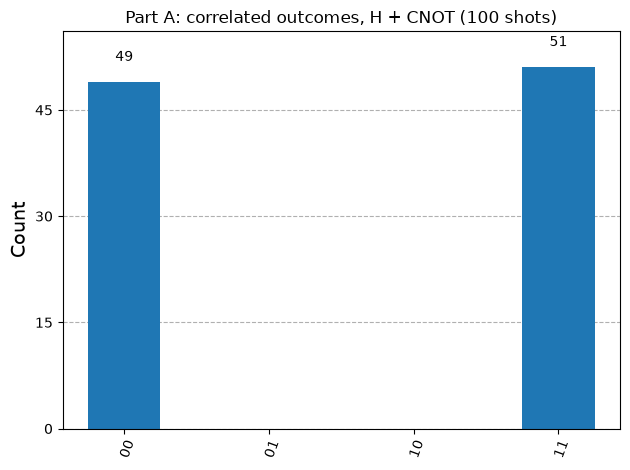

In [4]:
counts_a = run_circuit(qc_a)
print('Part A results (100 shots):', nonzero(counts_a))
display(plot_histogram(counts_a, title='Part A: correlated outcomes, H + CNOT (100 shots)'))

## Part B: Opposite outcomes (01 and 10)

**Circuit:** the Part A circuit with one **X gate on qubit 1** added after the CNOT, then measure both qubits. (3 gates before measurement)

In [5]:
# Part B circuit without measurement (for the exact prediction)
core_b = QuantumCircuit(2)
core_b.h(0)
core_b.cx(0, 1)
core_b.x(1)            # the switch

# Part B circuit that is executed
qc_b = QuantumCircuit(2, 2, name='Part B')
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)              # the switch
qc_b.measure([0, 1], [0, 1])

print('PART B CIRCUIT (opposite outcomes)')
print(qc_b.draw('text'))
pred_b = exact_probabilities(core_b)
print('\nPredicted probabilities:', {k: round(v, 3) for k, v in pred_b.items()})

PART B CIRCUIT (opposite outcomes)
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Predicted probabilities: {'00': 0.0, '01': 0.5, '10': 0.5, '11': 0.0}


Part B results (100 shots): {'01': 46, '10': 54}


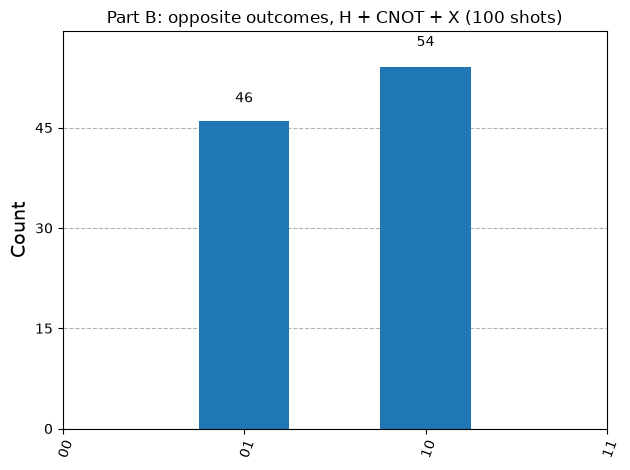

In [6]:
counts_b = run_circuit(qc_b)
print('Part B results (100 shots):', nonzero(counts_b))
display(plot_histogram(counts_b, title='Part B: opposite outcomes, H + CNOT + X (100 shots)'))

## Part C: Compare the two circuits

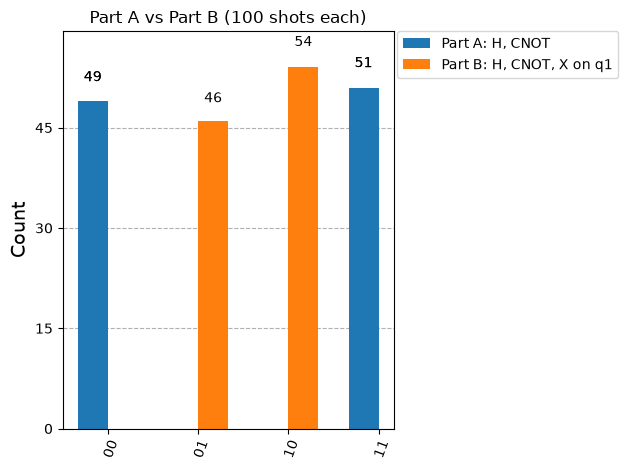

In [7]:
# Side-by-side histogram of Part A and Part B
display(plot_histogram(
    [counts_a, counts_b],
    legend=['Part A: H, CNOT', 'Part B: H, CNOT, X on q1'],
    title='Part A vs Part B (100 shots each)',
))

In [8]:
# Predicted vs actual, for both circuits
for name, pred, counts in [('Part A', pred_a, counts_a), ('Part B', pred_b, counts_b)]:
    print(f'{name}')
    print(f"  {'Outcome':<9}{'Predicted':<12}{'Actual (of 100)':<18}Match?")
    for s in STATES:
        print(f"  {s:<9}{pred[s] * SHOTS:<12.0f}{counts[s]:<18}{'YES' if within_noise(counts[s], pred[s]) else 'NO'}")
    print()

print(f"{'Circuit':<10}{'Qubits agree (00 or 11)':<26}{'Qubits differ (01 or 10)'}")
print('-' * 60)
for name, c in [('Part A', counts_a), ('Part B', counts_b)]:
    print(f"{name:<10}{c['00'] + c['11']:<26}{c['01'] + c['10']}")

Part A
  Outcome  Predicted   Actual (of 100)   Match?
  00       50          49                YES
  01       0           0                 YES
  10       0           0                 YES
  11       50          51                YES

Part B
  Outcome  Predicted   Actual (of 100)   Match?
  00       0           0                 YES
  01       50          46                YES
  10       50          54                YES
  11       0           0                 YES

Circuit   Qubits agree (00 or 11)   Qubits differ (01 or 10)
------------------------------------------------------------
Part A    100                       0
Part B    0                         100


## Explanation

**Which outcomes are dominant in Part A?** `00` and `11`, each about 50 out of 100. The qubits always agree (correlated).

**Which outcomes are dominant in Part B?** `01` and `10`, each about 50 out of 100. The qubits always disagree (opposite).

**What changed between the two circuits?** Only one extra gate: an **X gate on qubit 1**, placed after the CNOT and before measurement.

**Why did the measurement relationship change?**
- The Hadamard gate puts qubit 0 into an equal superposition of 0 and 1.
- The CNOT gate entangles the qubits, producing the Bell state (|00> + |11>)/sqrt(2). Each qubit alone is random, but the two always give the same value.
- The X gate flips qubit 1, turning |00> into |01> and |11> into |10>, so the state becomes (|01> + |10>)/sqrt(2). The qubits are still perfectly linked, but now they always give *different* values.
- The entanglement is unchanged; the X gate only switches the type of correlation from "same" to "opposite". This acts as a correlation switch.

**Prediction check:** the predictions held. In each circuit only two outcomes appeared, and the counts of those two outcomes are close to 50/50, with small run-to-run differences caused by random shot noise. (On real quantum hardware, noise could add a few shots to the other two outcomes, but an ideal simulator gives exactly zero.)